# Cylindrical refolded isocline — LDI fit

One **restore** event fitted to the sparse 3-D contacts and bedding from
`07a_cylindrical_isocline_data`, made cylindrical about the fold axis 07a decided. One model,
one fit, no ensemble.

**Cylindrical by construction.** The velocity is an Euler pair around the hinge: α is a cubic
random Fourier field whose wavevectors are drawn in the plane normal to the hinge
(`cylindrical=True`), and β is the distance along the hinge. Every velocity is then in the
fold profile and constant along the hinge, so the map, and every level surface, is a
cylinder about the hinge: exactly, whatever the data. Nothing is stretched or tuned along
the hinge, which is what an anisotropic interpolant needs to get close to the same thing.
The fit is the 2-D fit of the profile, made with the 3-D data.

**The restored layer-cake faces the spectral reference normal**, the best flat stack
read off the contacts and bedding in the profile (`BAND_INFO["normal"]`, younger side).
That normal is perpendicular to the hinge, so the map stays cylindrical. The identity
map already has that facing, and the flow then has no rigid rotation to build (a
rotation strains nothing, but it costs the energy bias a great deal).

**Training.** The energy-biased scheme of the other examples, with the settings of the 2-D
fit: energy-normalised cubic modes, amplitudes started at zero and trained by SGD with
momentum, phases and biases by Adam, and the one-way shear sweep (`N_STEPS = 0`).

**What this notebook is.** Computation and quick checks; the plots are not saved. Saved to
`results/`:

- `inputs.npz`: the evaluation grid and the sections the fits are scored on (read by
  `07c_cylindrical_isocline_surfe`, so Surfe runs on the same grid);
- `ldi.npz`: φ on the grid, the horizon isovalues, the restored contacts, the younging
  angles, the critical points and the section misfits;
- `ldi.json`: the comparison numbers; `fit_settings.json`; `restore.pt` (the model, meshed by
  `07d_cylindrical_isocline_meshes`).

## Setup

In [1]:
import json
import random
import warnings
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

import curlew
from curlew.core import CSet, HSet
from curlew.geometry import Grid
from curlew.geology import restore
from curlew.kinematics.euler import euler_velocity
from curlew.kinematics.training import SpectralWarmup
from curlew.priors.spectral import spectral_band, n_features_for_band
from curlew.io import saveModel

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
import isocline_inputs  # the processed data from 07a, and the comparison measures
from flat_reference import FlatReference   # in a module, so 07d can load the saved model
figstyle.apply()

curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 3

SEED = 404
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

OUT_DIR = isocline_inputs.RESULTS_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"device={curlew.device}, dtype={curlew.dtype}")

device=cpu, dtype=torch.float32


## Data and constraints

Each horizon is an equality (its contacts share one restored level); bedding normals are
matched after Nanson transport; younger-over-older pairs are available as inequalities
(`iq_loss`, off unless weighted below).

In [2]:
data = isocline_inputs.load_processed()
horizons, names = data["horizons"], data["horizon_names"]
gp, gv, hinge, u_ax, w_ax = data["gp"], data["gv"], data["hinge"], data["u_ax"], data["w_ax"]
box = data["box"]

IQ_SAMPLES = 64
C = CSet(gp=gp, gv=gv, eq=[h.astype(np.float32) for h in horizons], crs="model",   # already in the fitting frame
         iq=(IQ_SAMPLES, [(horizons[i], horizons[i + 1], ">") for i in range(len(horizons) - 1)]))
print(f"{len(horizons)} horizons ({sum(len(h) for h in horizons)} contacts), {len(gp)} bedding | "
      f"hinge {hinge.round(4)}")

3 horizons (102 contacts), 56 bedding | hinge [ 0.  1. -0.]


## Evaluation grid

The box from 07a at `STEP` m. `SECTIONS` sections normal to the hinge, evenly spread over
the data's extent along it, are where every fit is compared with the truth. The grid and
the sections are saved now, so Surfe runs on exactly this grid.

In [3]:
STEP = 10.0                # m
N_SECTIONS = 2

G = Grid(tuple(float(v) for v in np.ptp(box, axis=0)), step=(STEP,) * 3,
         center=tuple(box.mean(axis=0).tolist()), sampleArgs=dict(N=128))
domaxes = tuple(np.asarray(a, dtype=float) for a in G.tformed_axes)
x, y, z = domaxes
y_data = np.vstack(horizons)[:, 1]
sections = np.linspace(y_data.min(), y_data.max(), N_SECTIONS)
print("grid", G.shape, "step", G.step, "| sections at y =", sections.round(0))
np.savez_compressed(OUT_DIR / "inputs.npz", x=x, y=y, z=z, sections=sections, box=box)
print("wrote", OUT_DIR / "inputs.npz")

grid (60, 94, 80) step (10.0, 10.0, 10.0) | sections at y = [-370.  462.]
wrote results/inputs.npz


## Restore

The restored layer-cake faces the spectral reference normal (`BAND_INFO["normal"]`),
which lies in the profile, so a normal perpendicular to the hinge keeps the restore
cylindrical. `FlatReference` (`flat_reference.py`) is that layer cake, φ = *n* · *x*.
The other knobs are those of the 2-D fit.

In [4]:
# The wavelength band, read off the data's spectral moments (curlew.priors.spectral.spectral_band):
# contacts give the variance of horizon heights, bedding the variance of slopes, neighbouring
# bedding the variance of curvatures, measured in the profile plane (the hinge projected out).
# L_min is the shorter of the hinge spacing 2π√(m2/m4) and the limb spacing 2π√(m0/m2); L_max the
# longer, and at least two octaves above L_min and the data's diameter. The mode count follows
# from the band at a fixed number of modes per octave.
MODES_PER_OCTAVE = 128
N_DIRECTIONS = 32
with warnings.catch_warnings():
    # With three horizons the heights are under-sampled relative to λx, so λ0 is dropped and L_min is λx:
    # expected for this example, and in BAND_INFO (lambda_0 is None).
    warnings.filterwarnings("ignore", message="horizon heights are under-sampled")
    LSR, BAND_INFO = spectral_band(C, axis=hinge, return_info=True)
N_FEATURES = n_features_for_band(LSR, MODES_PER_OCTAVE, N_DIRECTIONS)
print(f"band {LSR[0]:.0f}-{LSR[1]:.0f} m | M {N_FEATURES} |", BAND_INFO)
N_STEPS = 0                # 0 = one-way shear sweep
EPOCHS = 3000
WEIGHTS = dict(grad_loss="1.", eq_loss="0.1")   
LR_ADAM = 5e-3            # Adam: phases and biases
LR_SGD = 1e-2              # SGD: mode amplitudes
AMP_MOMENTUM = 0.9
VELOCITY_SEED = 42404

band 584-2337 m | M 256 | {'m0': 17833.84635050669, 'm2': 3.1571206859097507, 'm4': 0.0003651445935485031, 'lambda_x': 584.2423343925882, 'lambda_0': None, 'normal': [-0.9407519604783487, 3.942372556424073e-10, -0.33909548633997366], 'normal_from_contacts': True, 'resolved': True, 'lambda_x_error': 0.3447048373466924, 'n_curvature': 25.688165436354144, 'window': None, 'contact_noise': None, 'n_eff': 1.0000000000000002, 'n_bedding': 56, 'n_contacts': 102, 'n_pairs': 50, 'n_windows': 0, 'n_horizons_spanning': 3, 'profile': True, 'diameter': 1200.5280447930777, 'curvature_modes': None, 'orientations_only': False, 'strain': None}


## Why L_min is set by hand

The data-derived band above takes L_min = λx = 2π√(m₂/m₄), the hinge spacing from a *mean-square*
curvature, so it is set by the sharpest hinges. Here the isocline's tight limbs face each other across a short
gap, and a few pairs of bedding readings across that gap carry nearly all of m₄. This cell shows, from the data
alone (nothing is fitted), where m₄ comes from, what wavelengths the bedding pairs see, and the scale of the
dense true contacts, against the L_min the fit uses (`L_MIN_HAND`; `BAND_HAND` takes L_max from the moments).

The wavelength a pair "sees" is 2π√m₂/κ, from its curvature κ and the data's rms tilt: a rough conversion,
good to about a factor of two. The fits tried by eye (section views, same seed, L_max unchanged) are marked.

data-derived L_min (λx) 584 m | by hand 700 m (1.2 times λx) | rms tilt 102°, λx resolved True (±0.34 octave)
50 curvature pairs: 7 turn more than 90° and carry 88% of m4; the largest pair alone carries 26%

wavelength the pairs see | pairs | mean turn | share of m4
      0-  500 m        |     9 |     138°  |    92%
    500- 1000 m        |     5 |      49°  |     5%
   1000- 2000 m        |     8 |      27°  |     2%
   2000- 5000 m        |    18 |      10°  |     1%
   5000-  inf m        |    10 |       3°  |     0%
pairs not across the gap: wavelengths they see, 25th / 50th / 75th percentile = 1461 / 2777 / 4439 m
true contacts: dominant wavelength of the tilt [1139, 1357, 1445] m (per unit arc length)


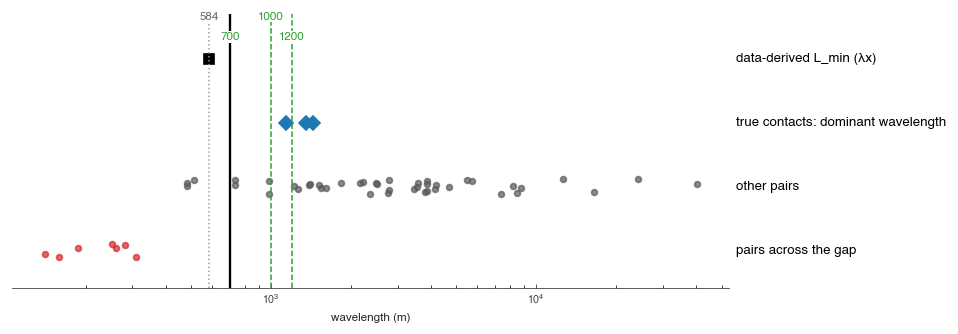

In [5]:
from scipy.ndimage import gaussian_filter1d
from scipy.signal import periodogram
from curlew.priors.spectral import spectral_moments

L_MIN_HAND = 700.0                          # set by hand
BAND_HAND = (L_MIN_HAND, float(LSR[1]))      # the range the velocity below uses: L_max from the moments (band above)
TRIED = {584: "data-derived: ragged kinks, pinched patch", 700: "smooth", 1000: "smoothest", 1200: "less good than 1000"}

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="horizon heights are under-sampled")
    mom = spectral_moments(C, axis=hinge, return_samples=True)
S = mom["samples"]
kappa, along = S["pair_curvature"], S["pair_distance"]
turn = np.degrees(kappa * along)                          # how far each pair's two normals turn
local = 2 * np.pi * np.sqrt(mom["m2"]) / kappa            # the wavelength each pair sees (rough)
share = kappa ** 2 / np.sum(kappa ** 2)                   # each pair's share of m4 (unweighted)
facing = turn > 90                                        # nearly opposite normals: the two limbs facing each other

print(f"data-derived L_min (λx) {mom['lambda_x']:.0f} m | by hand {BAND_HAND[0]:.0f} m ({BAND_HAND[0] / mom['lambda_x']:.1f} times λx) | "
      f"rms tilt {np.degrees(np.sqrt(mom['m2'])):.0f}°, λx resolved {mom['resolved']} (±{mom['lambda_x_error']:.2f} octave)")
print(f"{len(kappa)} curvature pairs: {facing.sum()} turn more than 90° and carry {share[facing].sum():.0%} of m4; "
      f"the largest pair alone carries {share.max():.0%}")
print("\nwavelength the pairs see | pairs | mean turn | share of m4")
for lo, hi in ((0, 500), (500, 1000), (1000, 2000), (2000, 5000), (5000, np.inf)):
    sel = (local >= lo) & (local < hi)
    print(f"  {lo:>5.0f}-{'inf' if np.isinf(hi) else format(hi, '.0f'):>5s} m        | {sel.sum():5d} | "
          f"{turn[sel].mean() if sel.any() else 0:7.0f}°  | {share[sel].sum():6.0%}")
bulk = local[~facing]
print(f"pairs not across the gap: wavelengths they see, 25th / 50th / 75th percentile = "
      f"{np.percentile(bulk, 25):.0f} / {np.percentile(bulk, 50):.0f} / {np.percentile(bulk, 75):.0f} m")

# The dense true contacts' own scale: the dominant wavelength of the tilt along each, per unit arc length.
g2 = np.array([S["normal"] @ u_ax, S["normal"] @ w_ax])
g2 /= np.linalg.norm(g2)
step, peaks = 8.0, []
for line in data["truth_lines"]:
    L = np.asarray(line)[0]
    s0 = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(L, axis=0), axis=1))]
    s = np.arange(0, s0[-1], step)
    T = gaussian_filter1d(np.c_[np.interp(s, s0, L[:, 0]), np.interp(s, s0, L[:, 1])], 1, axis=0, mode="nearest")
    tang = np.gradient(T, step, axis=0)
    tang /= np.linalg.norm(tang, axis=1, keepdims=True)
    nrm = np.c_[-tang[:, 1], tang[:, 0]]
    if np.mean(nrm @ g2) < 0:
        nrm = -nrm
    theta = np.unwrap(np.arctan2(g2[0] * nrm[:, 1] - g2[1] * nrm[:, 0], nrm @ g2))
    f, P = periodogram(theta - theta.mean(), fs=1 / step, window="hann", nfft=8 * len(theta))
    peaks.append(1 / f[1:][np.argmax(P[1:])])
print(f"true contacts: dominant wavelength of the tilt {np.round(peaks).astype(int).tolist()} m (per unit arc length)")

fig_why, ax_why = plt.subplots(figsize=(8, 2.8))
for row, (label, vals) in enumerate((("pairs across the gap", local[facing]), ("other pairs", bulk))):
    ax_why.plot(vals, np.full(len(vals), row) + np.random.default_rng(0).uniform(-0.12, 0.12, len(vals)), "o", ms=3.5,
                color="C3" if row == 0 else "0.35", alpha=0.7)
    ax_why.text(1.01, row, label, va="center", fontsize=8, transform=ax_why.get_yaxis_transform())
ax_why.plot(peaks, np.full(len(peaks), 2.0), "D", color="C0", ms=6)
ax_why.text(1.01, 2.0, "true contacts: dominant wavelength", va="center", fontsize=8, transform=ax_why.get_yaxis_transform())
ax_why.plot([mom["lambda_x"]], [3.0], "s", color="k", ms=6)
ax_why.text(1.01, 3.0, "data-derived L_min (λx)", va="center", fontsize=8, transform=ax_why.get_yaxis_transform())
for n_tried, l_min in enumerate(TRIED):
    ax_why.axvline(l_min, color="C2" if l_min >= 700 else "0.6", lw=0.9, ls="--" if l_min >= 700 else ":")
    ax_why.text(l_min, 3.62 if n_tried % 2 == 0 else 3.3, f"{l_min}", ha="center", fontsize=7, color="C2" if l_min >= 700 else "0.4",
            bbox=dict(fc="white", ec="none", pad=0.5))
ax_why.axvline(BAND_HAND[0], color="k", lw=1.4)
ax_why.set(xscale="log", yticks=[], xlabel="wavelength (m)", ylim=(-0.6, 3.7))
for side in ("left", "right", "top"):
    ax_why.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

In [6]:
# The layer-cake normal: the coordinate axis closest to the mean bedding normal (signed, so it faces the
# younger side), kept exactly in the profile so the cylindrical velocity does not have to rotate the package.
# The same rule gives the default depth axis of the other examples (01, 03, 04, 05, 06).
n_mean = (gv / np.linalg.norm(gv, axis=1, keepdims=True)).mean(axis=0)
k_axis = int(np.argmax(np.abs(n_mean)))
n_ref = np.zeros(3)
n_ref[k_axis] = np.sign(n_mean[k_axis])
print(f"mean bedding normal {n_mean.round(2)} (resultant length {np.linalg.norm(n_mean):.2f}) -> axis {'+-'[int(n_ref[k_axis] < 0)]}{'xyz'[k_axis]}, "
      f"{np.degrees(np.arccos(abs(n_mean[k_axis]) / np.linalg.norm(n_mean))):.0f}° from it; "
      f"the band's reference normal {np.round(BAND_INFO['normal'], 2)}")
n_ref = n_ref - hinge * np.dot(n_ref, hinge)
n_ref = n_ref / np.linalg.norm(n_ref)
reference = FlatReference(n_ref)
t_ref = np.cross(hinge, n_ref)             # in the profile, along the restored beds
print(f"reference normal {n_ref.round(4)} (from contacts: {BAND_INFO['normal_from_contacts']}), "
      f"angle with hinge {np.degrees(np.arcsin(np.clip(np.linalg.norm(np.cross(n_ref, hinge)), -1, 1))):.1f}°")

mean bedding normal [-0.09 -0.   -0.07] (resultant length 0.11) -> axis -x, 36° from it; the band's reference normal [-0.94  0.   -0.34]
reference normal [-1.  0. -0.] (from contacts: True), angle with hinge 90.0°


In [7]:
# Initialise velocity. Torch is seeded with the velocity seed, as 07e does for each member, so a member's seed
# gives the same fit here (set VELOCITY_SEED to it).
torch.manual_seed(VELOCITY_SEED)
velocity = euler_velocity(
    3, n_features=N_FEATURES, n_directions=N_DIRECTIONS, length_scale_range=BAND_HAND,
    stream="alpha", activation="cubic", seed=VELOCITY_SEED, hinge=hinge, cylindrical=True,
    energy_normalised=True,
)
event = restore(
    "cylindrical_isocline", C=C, H=HSet().zero(**WEIGHTS), velocity=velocity,
    n_steps=N_STEPS, integrator="shear", depth_axis=reference.depth_axis, reference=reference,
    init_std=0.0, sigma_floor=0.0, signed_normals=True, learning_rate=LR_ADAM,
    pin=torch.zeros(3, dtype=curlew.dtype, device=curlew.device),
    optimizer={"amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM, nesterov=True)),
               "shape": (torch.optim.Adam, dict(lr=LR_ADAM))},
)
for name, h in zip(names, horizons):
    event.addIsosurface(name, seed=h)

# Spectral warm-up (curlew.kinematics.training.SpectralWarmup): the octaves of the band are let in from
# the longest to the shortest, so the long modes build the fold and the short ones only refine it.
SPECTRAL_WARMUP = False
model = curlew.GeoModel([event])
with SpectralWarmup(event) as schedule:   # octaves open over the first 1/6 of the epochs
    model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True,
                 schedule=schedule if SPECTRAL_WARMUP else None)

L=0.003 grad_loss=0.001 eq_loss=0.001: : 3000/3000|


## Diagnostics

- **restored contacts**: each horizon pulled back through Φ⁻¹ should collapse to one
  restored level; its standard deviation is the misfit in metres;
- **younging**: the angle between the observed and predicted bedding normals (over 90° is a
  reversed way-up);
- **critical points** of φ in the volume; a diffeomorphic restore of a layer-cake has none;
- **against the truth** (`isocline_inputs.contact_misfit`), on each section: the distance from
  every dense truth contact to the model's contact there, and from the model's contact back
  to the truth (a contact the truth does not have, such as a bubble, scores far); and the
  intersection over union of each unit between two horizons with the true one, inside the
  bands the open truth lines close (`isocline_inputs.unit_iou`);
- **cylindricity**: `|∇φ·h| / |∇φ|` at `N_ALIGN` random grid points (0 where the level surface
  contains the hinge), and the fraction of grid lines along the hinge that change unit
  (`isocline_inputs.unit_change_along_hinge`). Both are zero for an exactly cylindrical fit, up to
  rounding.

In [8]:
N_ALIGN = 1_000

field = event.field
with torch.no_grad():
    restored = [field.inverse_map(torch.as_tensor(h, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
                for h in horizons]
    n_pred = field.predict_normals(torch.as_tensor(gp, dtype=curlew.dtype, device=curlew.device)).cpu().numpy()
    grd = torch.tensor(G.coords(), dtype=curlew.dtype, device=curlew.device)
    phi = G.reshape(np.asarray(model.predict(grd, litho=False).scalar, dtype=float))
iso = {str(k): float(v) for k, v in event.getIsovalues().items()}
isovalues = np.array([iso[n] for n in names])

level_mean = np.array([(r @ n_ref).mean() for r in restored])
level_sd = np.array([(r @ n_ref).std() for r in restored])
obs = gv
pred = n_pred / np.linalg.norm(n_pred, axis=1, keepdims=True).clip(min=1e-12)
cos = np.clip((obs * pred).sum(1), -1.0, 1.0)
younging = np.degrees(np.arctan2(np.linalg.norm(np.cross(obs, pred), axis=1), cos))
L_folded = np.ptp(np.vstack(horizons) @ t_ref)
L_restored = np.ptp(np.vstack(restored) @ t_ref)
crit = diagnostics.find_critical_points(event, *domaxes)

misfit = isocline_inputs.contact_misfit(x, y, z, phi, isovalues, data["truth_points"], sections)
change = isocline_inputs.unit_change_along_hinge(phi, isovalues)
iou = isocline_inputs.unit_iou(x, y, z, phi, isovalues, data["truth_lines"], sections)
rng = np.random.default_rng(SEED)
pts = G.coords()[rng.choice(len(G.coords()), N_ALIGN, replace=False)]
alignment = isocline_inputs.hinge_alignment(diagnostics.make_gradient_function(event, dim=3)(pts), hinge)
comparison = {"extrema": crit.counts, "younging_deg_median": float(np.median(younging)),
              "younging_deg_mean": float(younging.mean()), "fraction_reversed": float(np.mean(cos < 0)),
              "restored_level_sd_m": level_sd.tolist(),
              "shortening_pct": float((1.0 - L_folded / L_restored) * 100.0),
              **isocline_inputs.summarise(misfit, change, alignment, iou)}

for name, mu, sd in zip(names, level_mean, level_sd):
    print(f"{name:10s} restored level phi {mu:8.1f} m, sd {sd:6.1f} m")
print(f"younging angle: median {np.median(younging):.1f}°, mean {younging.mean():.1f}°, reversed {np.mean(cos < 0):.2f}")
print(f"shortening across the profile: {comparison['shortening_pct']:.1f}% | critical points: {crit.counts}")
print(f"truth contacts to the model: median {comparison['contact_to_model_m_median']:.1f} m, "
      f"90th pct {comparison['contact_to_model_m_p90']:.1f} m | model contacts to the truth: median "
      f"{comparison['isoline_to_truth_m_median']:.1f} m, 90th pct {comparison['isoline_to_truth_m_p90']:.1f} m")
print(f"IoU with the true units between the horizons (H0–H1, H1–H2, ...): "
      f"{np.round(comparison['unit_iou_median'], 2)} (median over the sections)")
print(f"cylindricity: |grad.h|/|grad| median {comparison['hinge_alignment_median']:.1e}, 95th pct "
      f"{comparison['hinge_alignment_p95']:.1e} | unit change along the hinge {comparison['unit_change_along_hinge_mean']:.4f} "
      f"({comparison['unit_change_along_hinge_lines_affected']:.1%} of lines)")

level 100  restored level phi    144.8 m, sd   12.6 m
level 50   restored level phi     90.0 m, sd    9.9 m
level 0    restored level phi     22.1 m, sd   15.4 m
younging angle: median 2.6°, mean 2.7°, reversed 0.00
shortening across the profile: 52.5% | critical points: {'maximum': 0, 'minimum': 0, 'saddle': 0, 'degenerate': 0}
truth contacts to the model: median 5.5 m, 90th pct 44.1 m | model contacts to the truth: median 5.4 m, 90th pct 20.2 m
IoU with the true units between the horizons (H0–H1, H1–H2, ...): [0.66 0.7 ] (median over the sections)
cylindricity: |grad.h|/|grad| median 4.1e-17, 95th pct 1.5e-16 | unit change along the hinge 0.0000 (0.0% of lines)


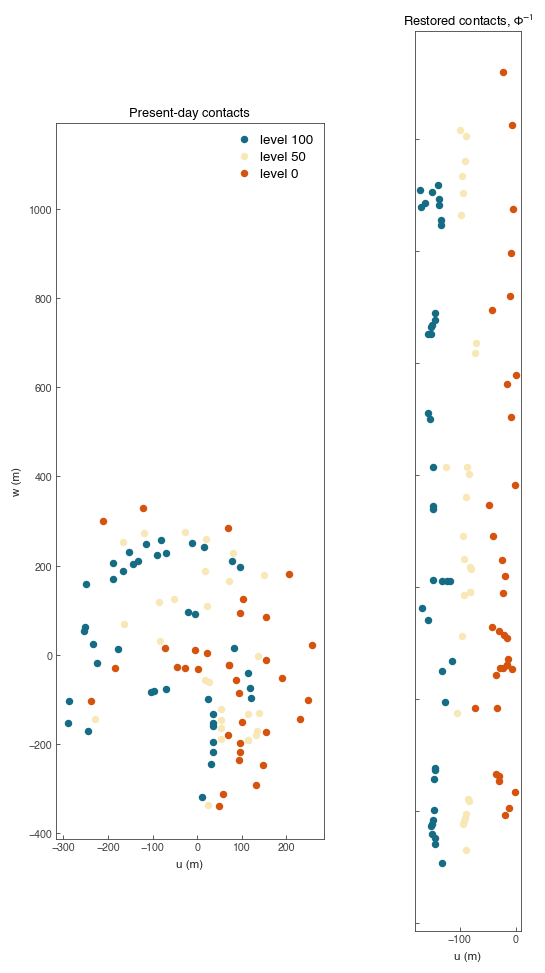

In [14]:
# Quick check (not saved): the contacts on the profile, as observed and restored.
colors = [figstyle.ramp()(t) for t in np.linspace(0.9, 0.1, len(horizons))]
fig, axs = plt.subplots(1, 2, figsize=(5, 8), constrained_layout=True, sharey=True)
for h, r, c, name in zip(horizons, restored, colors, names):
    axs[0].scatter(*isocline_inputs.to_profile(h, u_ax, w_ax).T, s=12, color=c, label=name)
    axs[1].scatter(*isocline_inputs.to_profile(r, u_ax, w_ax).T, s=12, color=c)
axs[0].set(title="Present-day contacts", xlabel="u (m)", ylabel="w (m)", aspect="equal")
axs[1].set(title=r"Restored contacts, $\Phi^{-1}$", xlabel="u (m)", aspect="equal")
axs[0].legend(frameon=False, fontsize=8)
plt.show()

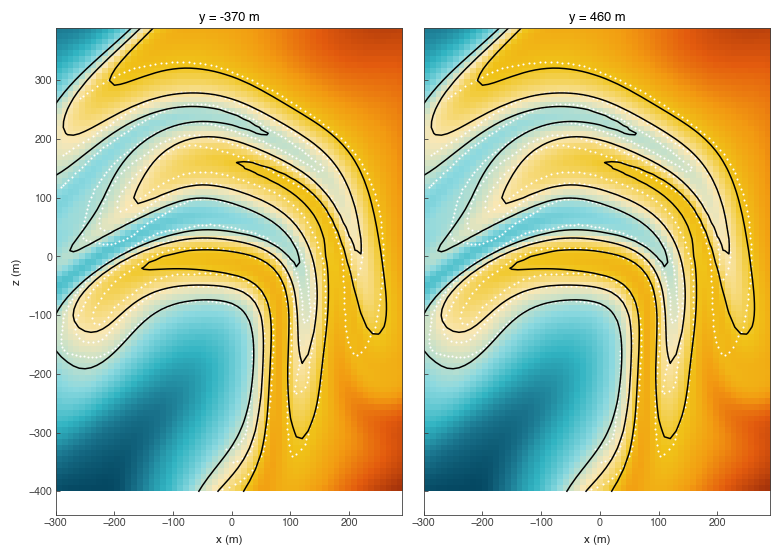

In [10]:
# Quick check (not saved): phi on the sections, the model's contacts (black) and the truth (white).
fig, axs = plt.subplots(1, len(sections), figsize=(3.2 * len(sections), 4.6), constrained_layout=True, sharey=True)
for ax, ys in zip(axs, sections):
    j = int(np.argmin(np.abs(y - ys)))
    ax.imshow(phi[:, j, :].T, origin="lower", extent=(x[0], x[-1], z[0], z[-1]), cmap=figstyle.ramp())
    for level in isovalues:
        for l in isocline_inputs.section_contours(x, z, phi[:, j, :], level):
            ax.plot(*l.T, color="k", lw=0.9)
    for p in data["truth_points"]:
        ax.scatter(*p.T, s=1.5, color="w", linewidths=0)
    ax.set(title=f"y = {y[j]:.0f} m", xlabel="x (m)")
axs[0].set_ylabel("z (m)")
plt.show()

In [ ]:
# Lithology of a saved ensemble member (07e's models), on a fine section; compare with this fit.
from curlew.io import loadModel
import flat_reference   # the saved models rebuild their reference from this module

MEMBER = 0            # index into the sorted saved models (see the printed list), or a seed number
SECTION = 0           # which section's y (the model is cylindrical, so any y inside the box gives the same picture)
STEP_FINE = 5.0       # m
CHUNK = 50_000

member_files = sorted((OUT_DIR / "ensemble" / "models").glob("member_*.pt"))
print(len(member_files), "saved members:", [f.stem.split("_")[1] for f in member_files])
path = next((f for f in member_files if f.stem == f"member_{MEMBER}"), None) or member_files[MEMBER]

y0 = float(y[int(np.argmin(np.abs(y - sections[SECTION])))])
xf = np.arange(x[0], x[-1] + 1e-9, STEP_FINE)
zf = np.arange(z[0], z[-1] + 1e-9, STEP_FINE)
XX, ZZ = np.meshgrid(xf, zf, indexing="ij")
pts = np.c_[XX.ravel(), np.full(XX.size, y0), ZZ.ravel()]

saved = loadModel(path)
lith = np.empty(len(pts), dtype=np.int16)
with torch.no_grad():
    for i in range(0, len(pts), CHUNK):
        chunk = torch.as_tensor(pts[i:i + CHUNK], dtype=curlew.dtype, device=curlew.device)
        lith[i:i + CHUNK] = np.asarray(saved.predict(chunk, litho=True).lithoID).ravel()
lith = lith.reshape(XX.shape)

ids = np.unique(lith)
cmap_lit, norm_lit = figstyle.litho_cmap(ids)
fig_lit, ax_lit = plt.subplots(figsize=(4.2, 5.0), constrained_layout=True)
im_lit = ax_lit.imshow(lith.T, origin="lower", extent=(x[0], x[-1], z[0], z[-1]), cmap=cmap_lit, norm=norm_lit,
                       interpolation="nearest", aspect="equal")
for h in data["truth_lines"]:                                   # the true contacts (profile = x, z)
    ax_lit.plot(*np.asarray(h[0]).T, color="k", lw=0.5, ls="--")
figstyle.set_view(ax_lit, (x[0], x[-1]), (z[0], z[-1]))         # stop at the image
fig_lit.colorbar(im_lit, ax=ax_lit, shrink=0.6, ticks=ids, label="unit")
ax_lit.set(title=f"{path.stem}, y = {y0:.0f} m (true contacts dashed)", xlabel="x (m)", ylabel="z (m)")
plt.show()


## Save

φ on the grid and each horizon's isovalue, the restored contacts and the diagnostics, the
comparison numbers, the settings and the model.

In [15]:
np.savez_compressed(
    OUT_DIR / "ldi.npz",
    phi=phi.astype(np.float32), isovalues=isovalues, reference_normal=n_ref,
    restored_level_mean=level_mean, restored_level_sd=level_sd,
    **{f"restored_{i}": r for i, r in enumerate(restored)},
    younging_angle=younging, unit_iou=iou, unit_change=change.astype(np.float32), hinge_alignment=alignment,
    **{f"misfit_{k}": v for k, v in misfit.items()}, **diagnostics.pack_critical(crit),
)
(OUT_DIR / "ldi.json").write_text(json.dumps({"comparison": comparison}, indent=1))
(OUT_DIR / "fit_settings.json").write_text(json.dumps(dict(
    seed=SEED, velocity_seed=VELOCITY_SEED, lsr=list(BAND_HAND), lsr_data_derived=list(LSR), n_features=N_FEATURES, n_directions=N_DIRECTIONS,
    modes_per_octave=MODES_PER_OCTAVE, band_info=BAND_INFO,
    n_steps=N_STEPS, epochs=EPOCHS, weights=WEIGHTS, iq_samples=IQ_SAMPLES, lr_adam=LR_ADAM, lr_sgd=LR_SGD,
    spectral_warmup=SPECTRAL_WARMUP, warmup_ramp=schedule.ramp,
    integrator="shear", cylindrical=True, energy_normalised=True, init_std=0.0,
    amp_momentum=AMP_MOMENTUM, reference_normal=n_ref.tolist(), hinge=hinge.tolist(),
    grid_step=STEP, sections=sections.tolist(), n_align=N_ALIGN,
), indent=2))
saveModel(OUT_DIR / "restore.pt", model)
print("wrote inputs.npz, ldi.npz, ldi.json, fit_settings.json, restore.pt to", OUT_DIR)

wrote inputs.npz, ldi.npz, ldi.json, fit_settings.json, restore.pt to results
